# 01 · Exploratory data analysis

**Goal:** understand the labelled freight data before any modelling: what each column holds, what is broken, and what drives `posted_rate`.

**Scope.** Only `data/train_test.csv` (48,000 labelled loads) is analysed. `data/validation.csv`, the 12,000 loads Spotter scores, is deliberately never opened here, so nothing about its contents can steer the decisions below.

**A note on "expected" prices.** Several sections compare a load's price with what similar loads cost. "Similar" comes from a simple regression on log price (distance, equipment, weight, cities, market index, date), used here purely as a measuring tool: it answers "what is left after accounting for distance, equipment, …?".

Every figure is saved to `reports/figures/eda/`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "train_test.csv").exists())
sys.path.insert(0, str(ROOT))

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from matplotlib.colors import TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch
from matplotlib.ticker import FixedLocator, FuncFormatter, MultipleLocator, NullLocator

from freight import style as S

S.apply_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

raw = pd.read_csv(ROOT / "data" / "train_test.csv", parse_dates=["date"])
print(raw.shape)
raw.head()

(48000, 14)


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


## 1 · First look

One row per load: where it goes (pickup and delivery city with coordinates), how far (`distance`, miles), what kind of trailer (`equipment`), how heavy (`weight`, lb), when (`date`), two market signals (`market_index`, `quote_signal`) and the target, `posted_rate` in dollars.

In [2]:
summary = pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing": raw.isna().sum(), "unique": raw.nunique()})
summary

,dtype,missing,unique
load_id,object,0,48000
pickup,object,0,64
delivery,object,0,64
pickup_lat,float64,0,64
pickup_lon,float64,0,63
delivery_lat,float64,0,64
delivery_lon,float64,0,63
distance,float64,0,21204
equipment,object,0,3
weight,float64,300,23678


In [3]:
raw.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
pickup_lat,48000.0,35.647545,28.35765,31.98691,35.29479,39.41104,44.30296,4.315285
pickup_lon,48000.0,-90.928964,-121.69849,-98.40059,-88.08915,-83.28506,-69.5,13.482431
delivery_lat,48000.0,35.641175,28.35765,31.98691,35.29479,39.41104,44.30296,4.317199
delivery_lon,48000.0,-90.85731,-121.69849,-98.40059,-87.52871,-83.28506,-69.5,13.476589
distance,48000.0,1135.856654,70.0,550.4,953.3,1645.525,3439.8,728.564416
weight,47700.0,31028.844004,-47500.0,25800.0,31436.5,37018.0,47500.0,9391.44062
date,48000,2025-05-31 19:53:29.400000,2025-01-01 00:00:00,2025-03-18 00:00:00,2025-05-31 00:00:00,2025-08-15 00:00:00,2025-10-31 00:00:00,NaN
market_index,47626.0,1.083387,0.67639,0.94967,1.0558,1.21959,1.46778,0.168091
quote_signal,48000.0,2.062468,0.69228,1.89103,2.05575,2.221685,3.61035,0.291391
posted_rate,48000.0,2373.980682,57.22,1251.555,2030.76,3330.75,25533.0,1486.493245


In [4]:
lanes = raw.groupby(["pickup", "delivery"]).size()
print(f"Dates: {raw.date.min():%Y-%m-%d} to {raw.date.max():%Y-%m-%d}, {raw.date.nunique()} distinct days (every calendar day present)")
print(f"Duplicate load_id: {raw.load_id.duplicated().sum()} | duplicate rows ignoring load_id: {raw.drop(columns='load_id').duplicated().sum()}")
print(f"load_id is in date order: {raw.sort_values('load_id').date.is_monotonic_increasing}")
print(f"Equipment values: {raw.equipment.value_counts().to_dict()}")
print(f"Cities: {raw.pickup.nunique()} pickup, {raw.delivery.nunique()} delivery, same-city loads: {(raw.pickup == raw.delivery).sum()}")
print(f"Lanes: {len(lanes):,} of {64 * 63:,} possible | loads per lane: median {lanes.median():.0f}, range {lanes.min()}–{lanes.max()}")
coords_per_city = raw.groupby("pickup")[["pickup_lat", "pickup_lon"]].nunique().max().max()
print(f"Distinct coordinate pairs per city: {coords_per_city} (each city has one fixed location)")

Dates: 2025-01-01 to 2025-10-31, 304 distinct days (every calendar day present)
Duplicate load_id: 0 | duplicate rows ignoring load_id: 0
load_id is in date order: True
Equipment values: {'Dry Van': 27202, 'Reefer': 12045, 'Flatbed': 8753}
Cities: 64 pickup, 64 delivery, same-city loads: 0
Lanes: 4,014 of 4,032 possible | loads per lane: median 10, range 1–39


Distinct coordinate pairs per city: 1 (each city has one fixed location)


**What this shows.** The file is tidy on the surface: no duplicates, three clean equipment labels, 64 cities with one fixed location each, and every day from 1 Jan to 31 Oct 2025. `load_id` is just a counter in date order, so it carries no information beyond the date. Two columns have gaps (`weight`, `market_index`), and the summary table already hints at trouble: weights go down to **−47,500 lb** and `posted_rate` runs from **$57 to $25,533**.

In [5]:
df = raw.copy()
df["month"] = df.date.dt.month
df["dow"] = df.date.dt.dayofweek
df["t"] = (df.date - df.date.min()).dt.days
df["log_rate"] = np.log(df.posted_rate)
df["log_dist"] = np.log(df.distance)
df["rate_per_mile"] = df.posted_rate / df.distance
df["weight_abs"] = df.weight.abs()
df["w_k"] = df.weight_abs.fillna(df.weight_abs.median()) / 1000  # thousands of lb, used only inside fits
df["mi_fill"] = df.market_index.fillna(df.groupby("date").market_index.transform("mean"))
quarter_end = df.date + pd.offsets.QuarterEnd(0)
df["days_to_qend"] = (quarter_end - df.date).dt.days

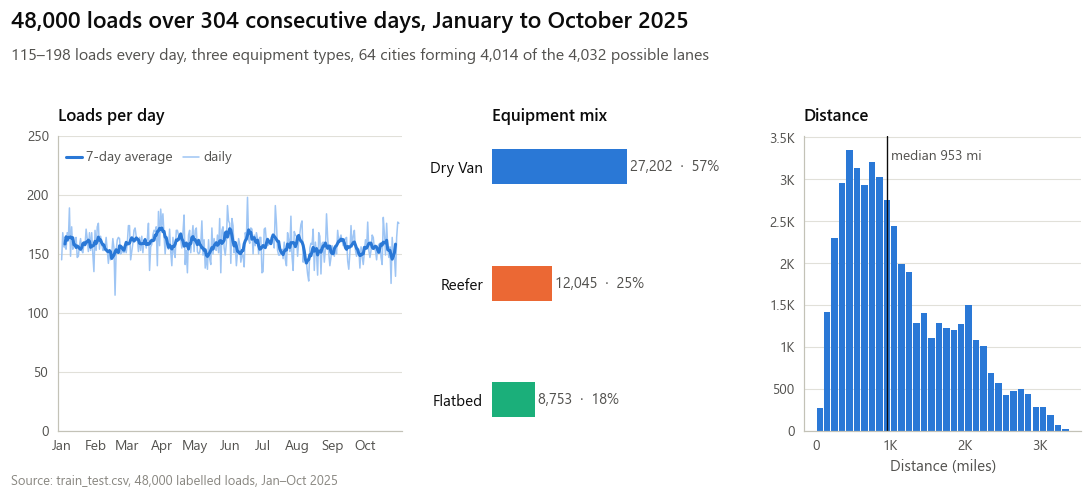

In [6]:
daily_n = df.groupby("date").size()
eq_counts = df.equipment.value_counts().reindex(S.EQUIPMENT_ORDER)

fig = plt.figure(figsize=(10, 4.6))
gs = fig.add_gridspec(1, 3, width_ratios=[1.55, 1, 1.25], left=0.055, right=0.985,
                      top=S.top(fig, 1.3), bottom=S.bottom(fig, 0.62), wspace=0.32)

ax = fig.add_subplot(gs[0])
ax.plot(daily_n.index, daily_n.values, color=S.BLUE_RAMP[1], lw=1)
roll = daily_n.rolling(7, center=True).mean()
ax.plot(roll.index, roll.values, color=S.BLUE, lw=2)
ax.set_ylim(0, 250)
ax.set_xlim(daily_n.index[0] - pd.Timedelta(days=3), daily_n.index[-1] + pd.Timedelta(days=3))
S.month_axis(ax)
x0 = daily_n.index[4]
ax.plot([x0, x0 + pd.Timedelta(days=14)], [232, 232], color=S.BLUE, lw=2)
ax.text(x0 + pd.Timedelta(days=18), 232, "7-day average", va="center", fontsize=9, color=S.INK_2)
ax.plot([x0 + pd.Timedelta(days=105), x0 + pd.Timedelta(days=119)], [232, 232], color=S.BLUE_RAMP[1], lw=1)
ax.text(x0 + pd.Timedelta(days=123), 232, "daily", va="center", fontsize=9, color=S.INK_2)
S.panel_title(ax, "Loads per day")

ax = fig.add_subplot(gs[1])
y = np.arange(len(eq_counts))[::-1]
ax.barh(y, eq_counts.values, height=0.3, color=[S.EQUIPMENT_COLORS[e] for e in eq_counts.index])
for yi, (name, n) in zip(y, eq_counts.items()):
    ax.text(n + 600, yi, f"{n:,}  ·  {n / len(df):.0%}", va="center", fontsize=9.5, color=S.INK_2)
ax.set_yticks(y, eq_counts.index)
ax.tick_params(axis="y", labelsize=10, labelcolor=S.INK)
ax.set_xlim(0, eq_counts.max() * 1.65)
ax.xaxis.set_major_locator(NullLocator())
ax.grid(False)
ax.spines["bottom"].set_visible(False)
ax.spines["left"].set_visible(False)
S.panel_title(ax, "Equipment mix")

ax = fig.add_subplot(gs[2])
ax.hist(df.distance, bins=np.arange(0, 3500, 100), color=S.BLUE, rwidth=0.86)
med = df.distance.median()
ax.axvline(med, color=S.INK, lw=0.9)
ax.text(med + 60, ax.get_ylim()[1] * 0.92, f"median {med:,.0f} mi", fontsize=9, color=S.INK_2)
S.thousands_axis(ax, "y")
ax.set_xlabel("Distance (miles)")
S.thousands_axis(ax, "x")
S.panel_title(ax, "Distance")

S.headline(fig, f"{len(df):,} loads over {df.date.nunique()} consecutive days, January to October 2025",
           f"{daily_n.min()}–{daily_n.max()} loads every day, three equipment types, 64 cities forming "
           f"{len(lanes):,} of the {64 * 63:,} possible lanes")
S.footnote(fig)
S.save(fig, "01_overview")
plt.show()

## 2 · Data quality

### 2.1 Corrupted prices

To judge whether a price is wrong we need an idea of what it *should* be. We fit a reference line on log price using distance, equipment, weight, market index, month, weekday and the two cities, then compare each load's actual price with that expectation. The fit is done twice: once on everything, then again after setting aside loads more than 1.5× away, so the outliers can't drag the reference.

In [7]:
REF = ("log_rate ~ bs(log_dist, df=6) + C(equipment) + bs(w_k, df=5) + mi_fill"
       " + C(month) + C(dow) + C(pickup) + C(delivery)")
first_pass = smf.ols(REF, df).fit()
keep = (df.log_rate - first_pass.predict(df)).abs() < np.log(1.5)
ref_fit = smf.ols(REF, df[keep]).fit()
df["expected"] = np.exp(ref_fit.predict(df))
df["ratio"] = df.posted_rate / df.expected
df["corrupt"] = np.log(df.ratio).abs() > np.log(1.5)

bands = pd.cut(df.ratio, [0, 1 / 2, 1 / 1.5, 1 / 1.15, 1.15, 1.5, 2, np.inf],
               labels=["< 0.5×", "0.5–0.67×", "0.67–0.87×", "within ±15%", "1.15–1.5×", "1.5–2×", "> 2×"])
print(bands.value_counts().sort_index().to_string())
print(f"\nTypical gap between actual and expected on normal loads: {np.log(df.loc[~df.corrupt, 'ratio']).std():.1%}")
low, high = df[df.ratio < 1], df[df.ratio > 1]
low_c, high_c = df[df.corrupt & (df.ratio < 1)], df[df.corrupt & (df.ratio > 1)]
print(f"Too low:  {len(low_c)} loads, {1 / low_c.ratio.max():.1f}× to {1 / low_c.ratio.min():.1f}× below expected")
print(f"Too high: {len(high_c)} loads, {high_c.ratio.min():.1f}× to {high_c.ratio.max():.1f}× above expected")
print(f"Largest normal deviation: {df.loc[~df.corrupt, 'ratio'].min():.2f}× to {df.loc[~df.corrupt, 'ratio'].max():.2f}×")

ratio
< 0.5×           337
0.5–0.67×          0
0.67–0.87×         0
within ±15%    47323
1.15–1.5×          0
1.5–2×             0
> 2×             340

Typical gap between actual and expected on normal loads: 2.0%
Too low:  337 loads, 2.3× to 5.8× below expected
Too high: 340 loads, 2.2× to 5.3× above expected
Largest normal deviation: 0.92× to 1.11×


The split is unusually clean: every load is either within about ±11% of its expected price or off by a factor of **2 to 6**. Nothing sits in between, so the threshold choice doesn't matter: any cut between 1.25× and 2× flags the same loads. Are the bad rows concentrated anywhere?

In [8]:
by = lambda col: df.groupby(col).corrupt.mean().mul(100).round(2)
print("Corrupted share (%) by month:     ", by("month").to_dict())
print("Corrupted share (%) by equipment: ", by("equipment").to_dict())
dist_q = pd.qcut(df.distance, 5, labels=["shortest fifth", "2nd", "3rd", "4th", "longest fifth"])
print("Corrupted share (%) by distance:  ", df.groupby(dist_q, observed=True).corrupt.mean().mul(100).round(2).to_dict())
print(f"Corrupted overall: {df.corrupt.mean():.2%}")

Corrupted share (%) by month:      {1: 1.65, 2: 1.31, 3: 1.41, 4: 1.37, 5: 1.26, 6: 1.32, 7: 1.32, 8: 1.43, 9: 1.37, 10: 1.65}
Corrupted share (%) by equipment:  {'Dry Van': 1.35, 'Flatbed': 1.45, 'Reefer': 1.51}
Corrupted share (%) by distance:   {'shortest fifth': 1.58, '2nd': 1.46, '3rd': 1.43, '4th': 1.35, 'longest fifth': 1.23}
Corrupted overall: 1.41%


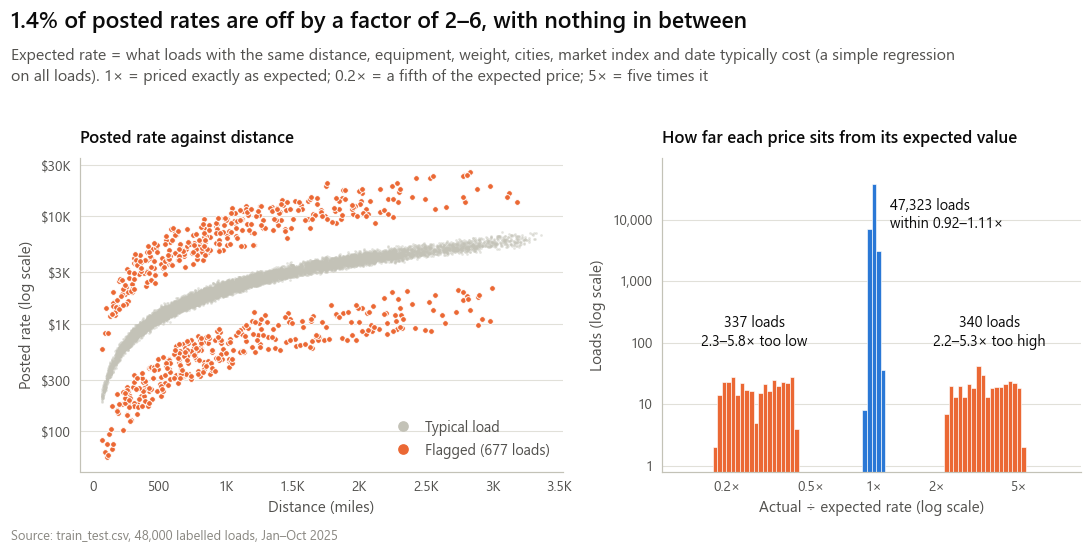

In [9]:
rng = np.random.default_rng(0)
ok = df[~df.corrupt]
sample = ok.iloc[rng.choice(len(ok), 14000, replace=False)]

fig = plt.figure(figsize=(10, 5.1))
gs = fig.add_gridspec(1, 2, width_ratios=[1.15, 1], left=0.075, right=0.985,
                      top=S.top(fig, 1.5), bottom=S.bottom(fig, 0.75), wspace=0.22)

ax = fig.add_subplot(gs[0])
ax.scatter(sample.distance, sample.posted_rate, s=3, color=S.NEUTRAL, alpha=0.45, linewidths=0, rasterized=True)
bad = df[df.corrupt]
ax.scatter(bad.distance, bad.posted_rate, s=14, color=S.ORANGE, edgecolors=S.SURFACE, linewidths=0.6, zorder=3)
ax.set_yscale("log")
ax.yaxis.set_major_locator(FixedLocator([100, 300, 1000, 3000, 10000, 30000]))
ax.yaxis.set_minor_locator(NullLocator())
S.dollar_axis(ax)
S.thousands_axis(ax, "x")
ax.set_xlabel("Distance (miles)")
ax.set_ylabel("Posted rate (log scale)")
ax.legend(handles=[Line2D([], [], ls="", marker="o", ms=6, color=S.NEUTRAL, label="Typical load"),
                   Line2D([], [], ls="", marker="o", ms=6, color=S.ORANGE, label=f"Flagged ({len(bad)} loads)")],
          loc="lower right")
S.panel_title(ax, "Posted rate against distance")

ax = fig.add_subplot(gs[1])
bins = np.exp(np.linspace(np.log(0.12), np.log(8), 85))
counts, edges = np.histogram(df.ratio, bins=bins)
centers = np.sqrt(edges[:-1] * edges[1:])
colors = [S.ORANGE if abs(np.log(c)) > np.log(1.5) else S.BLUE for c in centers]
ax.bar(edges[:-1], counts, width=np.diff(edges), align="edge", color=colors, edgecolor=S.SURFACE, linewidth=0.4)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_ylim(0.8, 1e5)
ax.xaxis.set_major_locator(FixedLocator([0.2, 0.5, 1, 2, 5]))
ax.xaxis.set_minor_locator(NullLocator())
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}×"))
ax.yaxis.set_major_locator(FixedLocator([1, 10, 100, 1000, 10000]))
ax.yaxis.set_minor_locator(NullLocator())
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlabel("Actual ÷ expected rate (log scale)")
ax.set_ylabel("Loads (log scale)")
n_ok = (~df.corrupt).sum()
ok_lo, ok_hi = df.loc[~df.corrupt, "ratio"].min(), df.loc[~df.corrupt, "ratio"].max()
ax.text(1.2, 1.2e4, f"{n_ok:,} loads\nwithin {ok_lo:.2f}–{ok_hi:.2f}×", ha="left", va="center",
        fontsize=9.5, color=S.INK)
ax.text(0.27, 90, f"{len(low_c)} loads\n{1 / low_c.ratio.max():.1f}–{1 / low_c.ratio.min():.1f}× too low",
        ha="center", fontsize=9.5, color=S.INK)
ax.text(3.6, 90, f"{len(high_c)} loads\n{high_c.ratio.min():.1f}–{high_c.ratio.max():.1f}× too high",
        ha="center", fontsize=9.5, color=S.INK)
S.panel_title(ax, "How far each price sits from its expected value")

S.headline(fig, f"{df.corrupt.mean():.1%} of posted rates are off by a factor of 2–6, with nothing in between",
           "Expected rate = what loads with the same distance, equipment, weight, cities, market index and date "
           "typically cost (a simple regression\non all loads). 1× = priced exactly as expected; "
           "0.2× = a fifth of the expected price; 5× = five times it")
S.footnote(fig)
S.save(fig, "02_label_corruption")
plt.show()

**What this means.** About 1 in 70 prices is wrong by a large multiplicative factor (roughly half too high, half too low), spread evenly across months, equipment types and distances: random corruption, not a real market pattern. Left in, these rows would pull any model towards nonsense prices. Because the bad rows sit so far from the rest, they can be identified reliably.

### 2.2 Weight

In [10]:
w = df.weight
print(f"Missing: {w.isna().sum()} | negative: {(w < 0).sum()} | exactly 47,500: {(w == 47500).sum()} | exactly −47,500: {(w == -47500).sum()} | exactly 5,000: {(w.abs() == 5000).sum()}")
print(f"Range of positive weights: {w[w > 0].min():,.0f} – {w[w > 0].max():,.0f}")
print(f"Share of weights that are round hundreds: {(w.dropna() % 100 == 0).mean():.1%} (so the spikes are not just rounding)")
print("Negative weights, absolute values:", w[w < 0].abs().describe().round(0).to_dict())

Missing: 300 | negative: 292 | exactly 47,500: 1191 | exactly −47,500: 13 | exactly 5,000: 32
Range of positive weights: 5,000 – 47,500
Share of weights that are round hundreds: 3.5% (so the spikes are not just rounding)
Negative weights, absolute values: {'count': 292.0, 'mean': 31724.0, 'std': 8263.0, 'min': 5000.0, '25%': 25928.0, '50%': 31822.0, '75%': 37284.0, 'max': 47500.0}


Three problems, plus missing values:
* **Negative weights (292).** Their absolute values look like ordinary weights (median ≈ 31,800 lb, same as the positive ones), which suggests a sign flip rather than garbage.
* **A cap at 47,500 lb (1,204 incl. 13 at −47,500).** A real distribution doesn't pile 2.5% of its mass on one exact value; anything heavier was recorded as 47,500.
* **A floor at 5,000 lb (32 incl. one at −5,000).** The same thing at the light end.

Does the sign-flip reading hold up? If it does, a "negative" load should be priced like a positive load of the same absolute weight.

In [11]:
clean = df[~df.corrupt].copy()
NO_WEIGHT = ("log_rate ~ bs(log_dist, df=6) + C(equipment) + mi_fill + C(month) + C(dow)"
             " + C(pickup) + C(delivery)")
fit_nw = smf.ols(NO_WEIGHT, clean).fit()
clean["r_nw"] = clean.log_rate - fit_nw.predict(clean)
clean["r_nw"] -= clean.r_nw.mean()

normal = clean[(clean.weight > 5000) & (clean.weight < 47500)]
wbins = np.arange(5000, 47501, 2500)
w_curve = normal.groupby(pd.cut(normal.weight, wbins), observed=True).agg(w=("weight", "mean"), r=("r_nw", "mean"), n=("r_nw", "size"))
neg = clean[clean.weight < 0]
neg_curve = neg.groupby(pd.cut(neg.weight_abs, np.arange(5000, 47501, 7500)), observed=True).agg(
    w=("weight_abs", "mean"), r=("r_nw", "mean"), n=("r_nw", "size"))
neg_curve = neg_curve[neg_curve.n >= 10]  # a single load per bin is too noisy to compare
capped = clean[clean.weight == 47500]
print(w_curve.round(4).to_string())
print("\nNegative weights (as absolute):\n", neg_curve.round(4).to_string())
print(f"\nCapped at 47,500: mean premium {capped.r_nw.mean():+.2%} vs {w_curve.r.iloc[-1]:+.2%} for 45,000–47,500")
print(f"Missing weight: mean premium {clean[clean.weight.isna()].r_nw.mean():+.2%} (≈ average load)")
for eq, g in normal.groupby("equipment"):
    print(f"{eq}: weight slope {np.polyfit(g.weight / 10000, g.r_nw, 1)[0]:+.2%} per 10,000 lb")

                         w       r     n
weight                                  
(5000, 7500]     6330.4667 -0.0423    45
(7500, 10000]    8975.2358 -0.0425   123
(10000, 12500]  11437.5292 -0.0454   274
(12500, 15000]  13928.5301 -0.0436   532
(15000, 17500]  16351.1085 -0.0415  1060
(17500, 20000]  18848.7396 -0.0395  1628
(20000, 22500]  21342.6093 -0.0354  2572
(22500, 25000]  23804.2090 -0.0288  3766
(25000, 27500]  26293.8065 -0.0205  4714
(27500, 30000]  28766.0352 -0.0099  5280
(30000, 32500]  31261.0633  0.0023  5605
(32500, 35000]  33742.3245  0.0125  5418
(35000, 37500]  36216.8877  0.0205  4808
(37500, 40000]  38688.7993  0.0263  3921
(40000, 42500]  41168.3818  0.0298  2839
(42500, 45000]  43652.0573  0.0310  1815
(45000, 47500]  46127.0519  0.0331  1137

Negative weights (as absolute):
                          w       r   n
weight_abs                            
(12500, 20000]  17223.4286 -0.0381  21
(20000, 27500]  24399.8358 -0.0259  67
(27500, 35000]  31490.5326  0.0

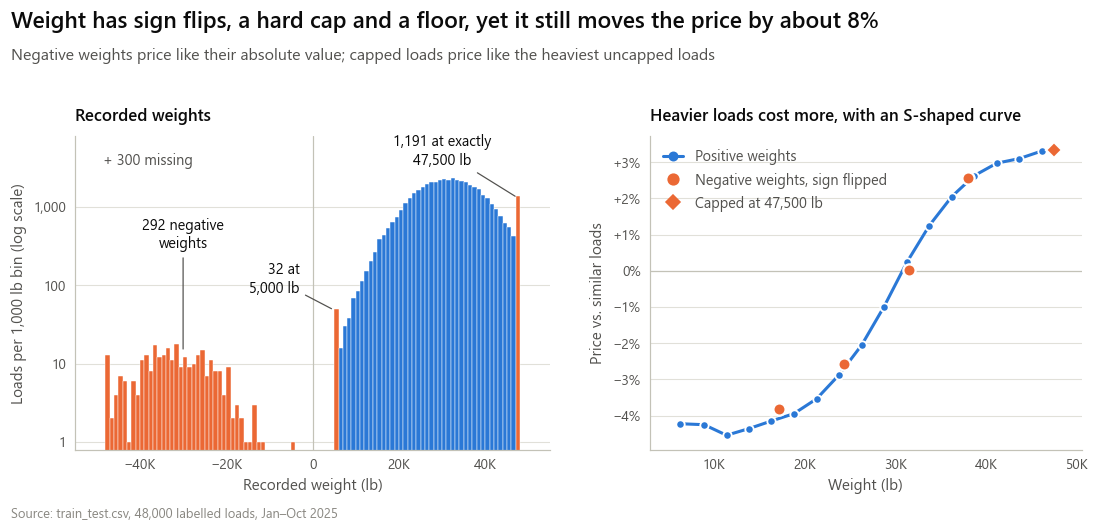

In [12]:
fig = plt.figure(figsize=(10, 4.9))
gs = fig.add_gridspec(1, 2, width_ratios=[1.1, 1], left=0.07, right=0.985,
                      top=S.top(fig, 1.3), bottom=S.bottom(fig, 0.75), wspace=0.22)

ax = fig.add_subplot(gs[0])
wb = np.arange(-50000, 50001, 1000)
counts, edges = np.histogram(w.dropna(), bins=wb)
def bin_color(lo):
    if lo < 0 or lo == 47000 or lo == 5000:
        return S.ORANGE
    return S.BLUE
ax.bar(edges[:-1], counts, width=1000, align="edge", color=[bin_color(lo) for lo in edges[:-1]],
       edgecolor=S.SURFACE, linewidth=0.3)
ax.set_yscale("log")
ax.set_ylim(0.8, 8000)
ax.yaxis.set_major_locator(FixedLocator([1, 10, 100, 1000]))
ax.yaxis.set_minor_locator(NullLocator())
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
S.thousands_axis(ax, "x")
ax.set_xlabel("Recorded weight (lb)")
ax.set_ylabel("Loads per 1,000 lb bin (log scale)")
ax.axvline(0, color=S.AXIS, lw=0.8)
ax.annotate(f"{(w < 0).sum()} negative\nweights", xy=(-30000, 14), xytext=(-30000, 300),
            ha="center", fontsize=9.5, color=S.INK, arrowprops=dict(arrowstyle="-", color=S.INK_2, lw=0.8))
ax.annotate(f"{(w == 47500).sum():,} at exactly\n47,500 lb", xy=(47500, 1300), xytext=(30000, 3500),
            ha="center", fontsize=9.5, color=S.INK, arrowprops=dict(arrowstyle="-", color=S.INK_2, lw=0.8))
ax.annotate(f"{(w.abs() == 5000).sum()} at\n5,000 lb", xy=(5000, 48), xytext=(-3000, 120),
            ha="right", va="center", fontsize=9.5, color=S.INK,
            arrowprops=dict(arrowstyle="-", color=S.INK_2, lw=0.8))
ax.text(-48500, 3500, f"+ {w.isna().sum()} missing", fontsize=9.5, color=S.INK_2)
S.panel_title(ax, "Recorded weights")

ax = fig.add_subplot(gs[1])
ax.plot(w_curve.w, w_curve.r, color=S.BLUE, lw=2, marker="o", ms=5.5, mec=S.SURFACE, mew=1.2, zorder=3)
ax.plot(neg_curve.w, neg_curve.r, ls="", marker="o", ms=8, color=S.ORANGE, mec=S.SURFACE, mew=1.5, zorder=4)
ax.plot([47500], [capped.r_nw.mean()], ls="", marker="D", ms=7.5, color=S.ORANGE, mec=S.SURFACE, mew=1.5, zorder=4)
ax.axhline(0, color=S.AXIS, lw=0.8)
S.pct_axis(ax, "y", signed=True)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1000:.0f}K"))
ax.set_xlabel("Weight (lb)")
ax.set_ylabel("Price vs. similar loads")
ax.set_xlim(3000, 50500)
ax.legend(handles=[Line2D([], [], color=S.BLUE, marker="o", ms=5.5, lw=2, label="Positive weights"),
                   Line2D([], [], ls="", marker="o", ms=7, color=S.ORANGE, label="Negative weights, sign flipped"),
                   Line2D([], [], ls="", marker="D", ms=6.5, color=S.ORANGE, label="Capped at 47,500 lb")],
          loc="upper left")
S.panel_title(ax, "Heavier loads cost more, with an S-shaped curve")

S.headline(fig, "Weight has sign flips, a hard cap and a floor, yet it still moves the price by about 8%",
           "Negative weights price like their absolute value; capped loads price like the heaviest uncapped loads")
S.footnote(fig)
S.save(fig, "03_weight")
plt.show()

**What this means.** Flipping the sign of negative weights gives prices consistent with ordinary loads (orange dots sit on the blue curve), so the fix is clear. The weight effect is real but non-linear: roughly flat below 20,000 lb, rising steeply to 40,000 lb, then levelling off. That is about 8% from light to heavy, the same for all three equipment types. Capped loads behave like the heaviest real loads, so the cap loses little information. Missing weights price like an average load (no hidden pattern).

### 2.3 Distance and coordinates

In [13]:
R_MILES = 3958.8
lat1, lon1, lat2, lon2 = (np.radians(df[c]) for c in ["pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon"])
a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
df["straight"] = 2 * R_MILES * np.arcsin(np.sqrt(a))
df["circuity"] = df.distance / df.straight
floor = df.distance == df.distance.min()
print(f"Minimum distance: {df.distance.min()} mi, shared by {floor.sum()} loads; next value up: {df.distance[~floor].min()}")
print(f"Correlation of distance with straight-line miles from the coordinates: {df.distance.corr(df.straight):.4f}")
print("Distance ÷ straight line (excluding the floor):", df.loc[~floor, "circuity"].quantile([.01, .25, .5, .75, .99]).round(3).to_dict())
lane_sd = df.groupby(["pickup", "delivery"]).distance.std()
print(f"Same lane, different loads: distance varies with a typical spread of {lane_sd.median():.0f} miles")
city_lon = df.groupby("pickup").pickup_lon.first()
print("Cities sitting exactly on the eastern longitude limit:", city_lon[city_lon == city_lon.max()].index.tolist(), city_lon.max())

Minimum distance: 70.0 mi, shared by 48 loads; next value up: 70.5
Correlation of distance with straight-line miles from the coordinates: 0.9995
Distance ÷ straight line (excluding the floor): {0.01: 1.13, 0.25: 1.165, 0.5: 1.182, 0.75: 1.205, 0.99: 1.395}
Same lane, different loads: distance varies with a typical spread of 16 miles
Cities sitting exactly on the eastern longitude limit: ['Boston', 'Providence'] -69.5


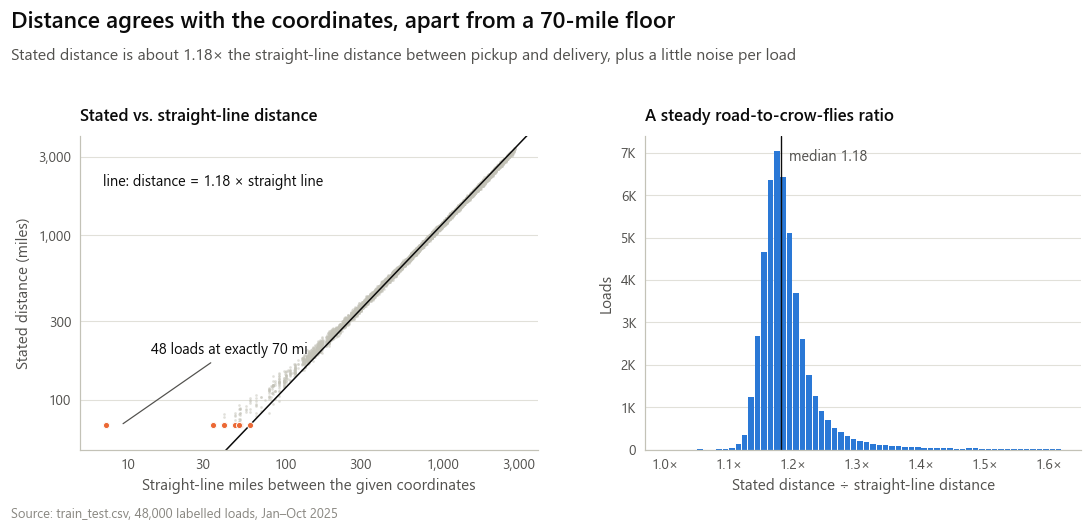

In [14]:
fig = plt.figure(figsize=(10, 4.9))
gs = fig.add_gridspec(1, 2, width_ratios=[1.05, 1], left=0.075, right=0.985,
                      top=S.top(fig, 1.3), bottom=S.bottom(fig, 0.75), wspace=0.24)

ax = fig.add_subplot(gs[0])
s = df[~floor].iloc[rng.choice((~floor).sum(), 12000, replace=False)]
ax.scatter(s.straight, s.distance, s=3, color=S.NEUTRAL, alpha=0.5, linewidths=0, rasterized=True)
ax.scatter(df.loc[floor, "straight"], df.loc[floor, "distance"], s=16, color=S.ORANGE, edgecolors=S.SURFACE,
           linewidths=0.6, zorder=3)
k = df.loc[~floor, "circuity"].median()
xx = np.array([5, 3500])
ax.plot(xx, k * xx, color=S.INK, lw=1)
ax.set_xscale("log")
ax.set_yscale("log")
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_locator(FixedLocator([10, 30, 100, 300, 1000, 3000]))
    axis.set_minor_locator(NullLocator())
    axis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlim(5, 4000)
ax.set_ylim(50, 4000)
ax.set_xlabel("Straight-line miles between the given coordinates")
ax.set_ylabel("Stated distance (miles)")
ax.text(7, 2000, f"line: distance = {k:.2f} × straight line", fontsize=9.5, color=S.INK)
ax.annotate(f"{floor.sum()} loads at exactly {df.distance.min():.0f} mi", xy=(9, 70), xytext=(14, 190),
            fontsize=9.5, color=S.INK, arrowprops=dict(arrowstyle="-", color=S.INK_2, lw=0.8))
S.panel_title(ax, "Stated vs. straight-line distance")

ax = fig.add_subplot(gs[1])
ax.hist(df.loc[~floor, "circuity"], bins=np.arange(1.0, 1.62, 0.01), color=S.BLUE, rwidth=0.85)
ax.axvline(k, color=S.INK, lw=0.9)
ax.text(k + 0.012, ax.get_ylim()[1] * 0.92, f"median {k:.2f}", fontsize=9.5, color=S.INK_2)
S.thousands_axis(ax, "y")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.1f}×"))
ax.set_xlabel("Stated distance ÷ straight-line distance")
ax.set_ylabel("Loads")
S.panel_title(ax, "A steady road-to-crow-flies ratio")

S.headline(fig, f"Distance agrees with the coordinates, apart from a {df.distance.min():.0f}-mile floor",
           f"Stated distance is about {k:.2f}× the straight-line distance between pickup and delivery, "
           "plus a little noise per load")
S.footnote(fig)
S.save(fig, "04_distance_checks")
plt.show()

**What this means.** Stated distance is almost exactly the straight-line distance between the given coordinates times a "road factor" of about 1.18, plus a little per-load noise (the same lane varies by ~16 miles between loads). Very short lanes are clamped to a **70-mile floor**. Two cities (Boston, Providence) sit exactly on the same eastern longitude limit, so the coordinates were clipped to a boundary there. Otherwise distance and coordinates tell the same story.

### 2.4 Missing values and the full data-quality picture

In [15]:
issues = {
    "Weight capped at 47,500 lb": df.weight_abs == 47500,
    "Posted rate off by 2–6×": df.corrupt,
    "Market index missing": df.market_index.isna(),
    "Weight missing": df.weight.isna(),
    "Weight negative (sign flip)": df.weight < 0,
    "Distance at 70-mile floor": floor,
    "Weight at 5,000 lb floor": df.weight_abs == 5000,
}
issue_counts = pd.Series({k: v.sum() for k, v in issues.items()}).sort_values(ascending=False)
any_issue = np.logical_or.reduce(list(issues.values()))
print(issue_counts.to_string())
print(f"\nLoads with at least one issue: {any_issue.sum():,} ({any_issue.mean():.1%})")
print(f"Weight and market index both missing: {(df.weight.isna() & df.market_index.isna()).sum()} "
      f"(≈{df.weight.isna().mean() * df.market_index.isna().mean() * len(df):.1f} expected by chance)")
print(f"Market index on loads where it is missing could be recovered from the same day's other loads: "
      f"day-to-day spread {df.groupby('date').market_index.mean().std():.3f} vs within-day spread "
      f"{(df.market_index - df.groupby('date').market_index.transform('mean')).std():.3f}")
print(f"Price of loads with missing market index vs. similar loads: "
      f"{(np.log(df.loc[df.market_index.isna() & ~df.corrupt, 'ratio'])).mean():+.2%}")

Weight capped at 47,500 lb     1204
Posted rate off by 2–6×         677
Market index missing            374
Weight missing                  300
Weight negative (sign flip)     292
Distance at 70-mile floor        48
Weight at 5,000 lb floor         32

Loads with at least one issue: 2,863 (6.0%)
Weight and market index both missing: 1 (≈2.3 expected by chance)
Market index on loads where it is missing could be recovered from the same day's other loads: day-to-day spread 0.167 vs within-day spread 0.025
Price of loads with missing market index vs. similar loads: -0.01%


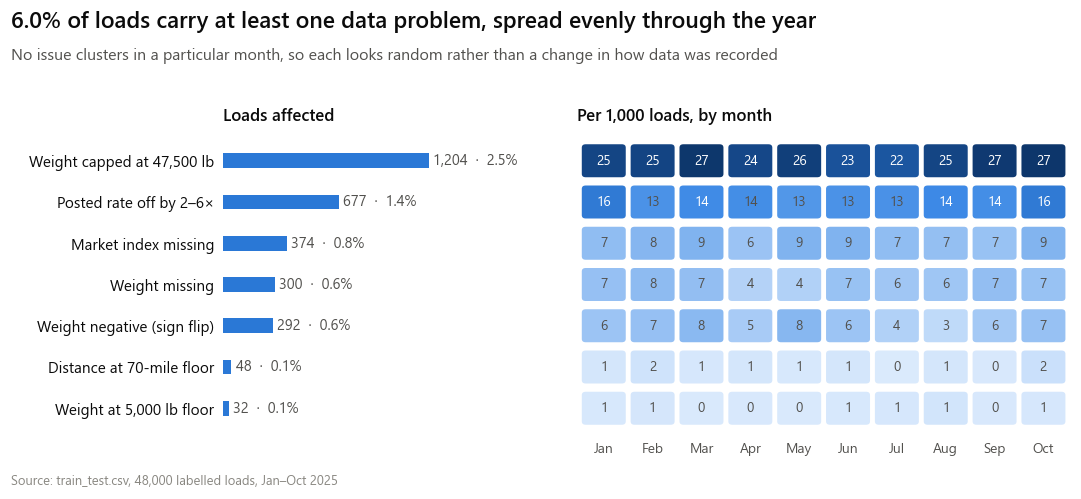

In [16]:
month_rate = pd.DataFrame({k: v.groupby(df.month).mean() * 1000 for k, v in issues.items()})[issue_counts.index].T

fig = plt.figure(figsize=(10, 4.6))
gs = fig.add_gridspec(1, 2, width_ratios=[0.8, 1.2], left=0.205, right=0.975,
                      top=S.top(fig, 1.3), bottom=S.bottom(fig, 0.6), wspace=0.06)

y = np.arange(len(issue_counts))[::-1]
ax = fig.add_subplot(gs[0])
ax.barh(y, issue_counts.values, height=0.36, color=S.BLUE)
for yi, n in zip(y, issue_counts.values):
    ax.text(n + 25, yi, f"{n:,}  ·  {n / len(df):.1%}", va="center", fontsize=9.5, color=S.INK_2)
ax.set_yticks(y, issue_counts.index)
ax.tick_params(axis="y", labelsize=10, labelcolor=S.INK)
ax.set_xlim(0, issue_counts.max() * 1.6)
ax.set_ylim(-0.6, len(issue_counts) - 0.4)
ax.xaxis.set_major_locator(NullLocator())
ax.grid(False)
for side in ("bottom", "left"):
    ax.spines[side].set_visible(False)
S.panel_title(ax, "Loads affected")

ax = fig.add_subplot(gs[1])
vmax = month_rate.values.max()
n_rows = month_rate.shape[0]
for i in range(n_rows):
    for j in range(month_rate.shape[1]):
        v = month_rate.values[i, j]
        yy = n_rows - 1 - i
        ax.add_patch(FancyBboxPatch((j - 0.45, yy - 0.4), 0.9, 0.8, boxstyle="round,pad=0,rounding_size=0.08",
                                    facecolor=S.SEQUENTIAL(0.08 + 0.92 * v / vmax), linewidth=0))
        ax.text(j, yy, f"{v:.0f}", ha="center", va="center", fontsize=8.8,
                color=S.SURFACE if v > vmax * 0.5 else S.INK_2)
ax.set_xlim(-0.55, 9.55)
ax.set_ylim(-0.6, n_rows - 0.4)
ax.set_xticks(range(10), [pd.Timestamp(2025, m, 1).strftime("%b") for m in month_rate.columns])
ax.set_yticks([])
ax.tick_params(axis="x", labelsize=9)
ax.grid(False)
for sp in ax.spines.values():
    sp.set_visible(False)
S.panel_title(ax, "Per 1,000 loads, by month")

S.headline(fig, f"{any_issue.mean():.1%} of loads carry at least one data problem, spread evenly through the year",
           "No issue clusters in a particular month, so each looks random rather than a change in how data was recorded")
S.footnote(fig)
S.save(fig, "05_data_quality_summary")
plt.show()

**What this means.** The problems are rare and evenly spread, with no month where something "broke". Missing values look random too: they don't coincide with each other more than chance, and loads with a missing market index are priced like everyone else. Because `market_index` is mostly a *daily* number (it varies far more between days than within a day), a missing value can be estimated from other loads on the same day.

## 3 · What drives the price

From here on the 677 corrupted prices are set aside, so the patterns reflect real pricing.

### 3.1 Distance and equipment

In [17]:
dbins = np.r_[60, np.arange(150, 3501, 100)]
clean["dbin"] = pd.cut(clean.distance, dbins)
by_eq = clean.groupby(["equipment", "dbin"], observed=True).agg(
    d=("distance", "median"), rate=("posted_rate", "median"), rpm=("rate_per_mile", "median"), n=("posted_rate", "size"))
by_eq = by_eq[by_eq.n >= 25]

dq = pd.qcut(clean.distance, 8)
prem = clean.groupby([dq, "equipment"], observed=True).posted_rate.median().unstack()
prem_rel = prem[["Reefer", "Flatbed"]].div(prem["Dry Van"], axis=0) - 1
prem_rel["d"] = clean.groupby(dq, observed=True).distance.median().values
print(prem_rel.round(3).to_string())
for eq, g in clean.groupby("equipment"):
    b = np.polyfit(g.distance, g.posted_rate, 1)
    print(f"{eq:8s} rate ≈ ${b[1]:.0f} + ${b[0]:.2f} per mile | median ${g.rate_per_mile.median():.2f}/mi")
print(f"Share of variation in log price explained by distance alone: {smf.ols('log_rate ~ bs(log_dist, df=6)', clean).fit().rsquared:.1%}")

equipment           Reefer  Flatbed        d
distance                                    
(69.999, 367.025]    0.128    0.091   264.60
(367.025, 550.8]     0.128    0.087   459.40
(550.8, 752.0]       0.133    0.083   656.65
(752.0, 954.1]       0.133    0.076   845.10
(954.1, 1212.0]      0.137    0.084  1066.00
(1212.0, 1647.6]     0.125    0.081  1405.00
(1647.6, 2104.175]   0.133    0.084  1885.40
(2104.175, 3439.8]   0.130    0.089  2442.80
Dry Van  rate ≈ $247 + $1.75 per mile | median $2.05/mi
Flatbed  rate ≈ $265 + $1.90 per mile | median $2.22/mi
Reefer   rate ≈ $281 + $1.98 per mile | median $2.31/mi


Share of variation in log price explained by distance alone: 98.7%


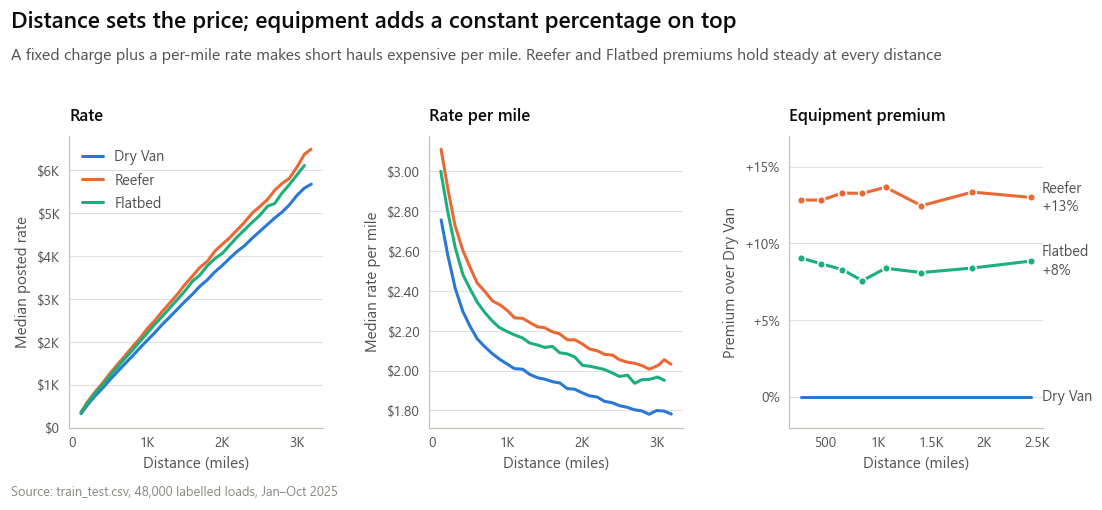

In [18]:
fig = plt.figure(figsize=(10, 4.7))
gs = fig.add_gridspec(1, 3, left=0.065, right=0.95, top=S.top(fig, 1.3), bottom=S.bottom(fig, 0.75), wspace=0.42)

ax = fig.add_subplot(gs[0])
for eq in S.EQUIPMENT_ORDER:
    g = by_eq.loc[eq]
    ax.plot(g.d, g.rate, color=S.EQUIPMENT_COLORS[eq], lw=2)
S.dollar_axis(ax)
S.thousands_axis(ax, "x")
ax.set_xlabel("Distance (miles)")
ax.set_ylabel("Median posted rate")
ax.set_ylim(0, None)
ax.legend(handles=[Line2D([], [], color=S.EQUIPMENT_COLORS[e], lw=2, label=e) for e in S.EQUIPMENT_ORDER],
          loc="upper left")
S.panel_title(ax, "Rate")

ax = fig.add_subplot(gs[1])
for eq in S.EQUIPMENT_ORDER:
    g = by_eq.loc[eq]
    ax.plot(g.d, g.rpm, color=S.EQUIPMENT_COLORS[eq], lw=2)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:.2f}"))
S.thousands_axis(ax, "x")
ax.set_xlabel("Distance (miles)")
ax.set_ylabel("Median rate per mile")
S.panel_title(ax, "Rate per mile")

ax = fig.add_subplot(gs[2])
for eq in ["Reefer", "Flatbed"]:
    ax.plot(prem_rel.d, prem_rel[eq], color=S.EQUIPMENT_COLORS[eq], lw=2, marker="o", ms=5, mec=S.SURFACE, mew=1)
    ax.text(prem_rel.d.iloc[-1] * 1.04, prem_rel[eq].iloc[-1], f"{eq}\n{prem_rel[eq].median():+.0%}",
            va="center", fontsize=9.5, color=S.INK_2)
ax.plot([prem_rel.d.iloc[0], prem_rel.d.iloc[-1]], [0, 0], color=S.EQUIPMENT_COLORS["Dry Van"], lw=2)
ax.text(prem_rel.d.iloc[-1] * 1.04, 0, "Dry Van", va="center", fontsize=9.5, color=S.INK_2)
ax.set_ylim(-0.02, 0.17)
ax.yaxis.set_major_locator(MultipleLocator(0.05))
S.pct_axis(ax, "y", signed=True)
S.thousands_axis(ax, "x")
ax.set_xlabel("Distance (miles)")
ax.set_ylabel("Premium over Dry Van")
S.panel_title(ax, "Equipment premium")

S.headline(fig, "Distance sets the price; equipment adds a constant percentage on top",
           "A fixed charge plus a per-mile rate makes short hauls expensive per mile. "
           "Reefer and Flatbed premiums hold steady at every distance")
S.footnote(fig)
S.save(fig, "06_distance_equipment")
plt.show()

**What this means.** Distance is by far the biggest driver: on its own it explains about 99% of the variation in log price. Pricing looks like *a fixed charge (≈ $250) plus a per-mile rate (≈ $1.75–2.00)*, which is why short hauls cost much more per mile. Equipment multiplies the price by a constant factor (Reefer ≈ +13%, Flatbed ≈ +8%), so equipment effects are proportional, not fixed-dollar.

### 3.2 Geography

After accounting for distance, equipment, weight, market index and calendar, does it matter which city a load starts or ends in? The reference fit from section 2.1 includes a term for each pickup and each delivery city; those terms are the "city effects".

In [19]:
def city_effects(fit, side):
    prefix = f"C({side})[T."
    eff = {k[len(prefix):-1]: v for k, v in fit.params.items() if k.startswith(prefix)}
    s = pd.Series({c: eff.get(c, 0.0) for c in sorted(df[side].unique())})
    return s - s.mean()

clean_fit = smf.ols(REF, clean).fit()
cities = df.groupby("pickup")[["pickup_lat", "pickup_lon"]].first().rename(columns=lambda c: c.split("_")[1])
cities["as_pickup"] = city_effects(clean_fit, "pickup")
cities["as_delivery"] = city_effects(clean_fit, "delivery")
cities["effect"] = cities[["as_pickup", "as_delivery"]].mean(axis=1)
cities["loads"] = df.pickup.value_counts() + df.delivery.value_counts()
surface = smf.ols("effect ~ lat + lon + I(lat**2) + I(lon**2) + lat:lon", cities).fit()
r_sym = cities.as_pickup.corr(cities.as_delivery)
print(f"Correlation of a city's effect as origin vs. as destination: {r_sym:.3f}")
print(f"Share of city effects explained by a smooth surface over latitude/longitude: {surface.rsquared:.0%}")
print(f"City effects range from {cities.effect.min():+.1%} to {cities.effect.max():+.1%} (spread {cities.effect.std():.1%})")
print(cities.sort_values("effect")[["effect", "loads"]].iloc[np.r_[0:6, -6:0]].round(3).to_string())

Correlation of a city's effect as origin vs. as destination: 0.991
Share of city effects explained by a smooth surface over latitude/longitude: 83%
City effects range from -3.7% to +3.2% (spread 1.9%)
               effect  loads
pickup                      
Syracuse       -0.037   1833
Albany         -0.032   1623
Buffalo        -0.032   1491
Detroit        -0.031    644
Reno           -0.026   1295
Harrisburg     -0.025   1114
Tulsa           0.028   1280
San Antonio     0.029   1937
Lubbock         0.029   1550
Dallas          0.030    582
Houston         0.030   1441
Oklahoma City   0.032   2382


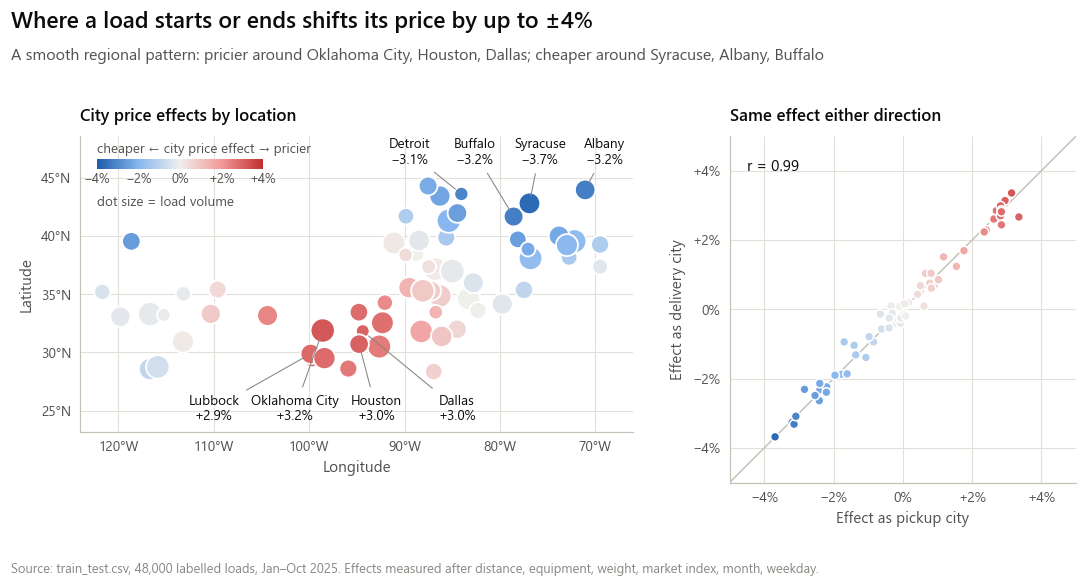

In [20]:
fig = plt.figure(figsize=(10, 5.4))
gs = fig.add_gridspec(1, 2, width_ratios=[1.55, 1], left=0.075, right=0.985,
                      top=S.top(fig, 1.3), bottom=S.bottom(fig, 0.95), wspace=0.2)
lim = 0.04
norm = TwoSlopeNorm(0, -lim, lim)

ax = fig.add_subplot(gs[0])
sizes = 25 + 230 * cities.loads / cities.loads.max()
sc = ax.scatter(cities.lon, cities.lat, s=sizes, c=cities.effect, cmap=S.DIVERGING, norm=norm,
                edgecolors=S.SURFACE, linewidths=1.2, zorder=3)
ordered = cities.sort_values("effect")
labelled = pd.concat([ordered.head(4), ordered.tail(4)])
# Cheapest cities sit in the north-east, priciest in the south: labels go in a row above / below the map,
# ordered west to east so the leader lines never cross.
label_lat = {"north": 46.0, "south": 26.4}
for side, group in [("north", ordered.head(4)), ("south", ordered.tail(4))]:
    xs = np.linspace(-89.5, -69, 4) if side == "north" else np.linspace(-110, -84.5, 4)
    for x_text, (name, row) in zip(xs, group.sort_values("lon").iterrows()):
        ax.annotate(f"{name}\n{S.pct(row.effect, 1, signed=True)}", (row.lon, row.lat),
                    xytext=(x_text, label_lat[side]), ha="center", va="bottom" if side == "north" else "top",
                    fontsize=8.8, color=S.INK, linespacing=1.25, zorder=4,
                    arrowprops=dict(arrowstyle="-", color=S.MUTED, lw=0.7, shrinkA=3, shrinkB=5))
ax.set_xlim(-124, -66)
ax.set_ylim(23.2, 48.6)
ax.set_aspect(1.22)
ax.set_anchor("N")
ax.xaxis.set_major_locator(MultipleLocator(10))
ax.yaxis.set_major_locator(MultipleLocator(5))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{abs(v):.0f}°W"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}°N"))
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.grid(True, axis="both")
cax = ax.inset_axes([0.03, 0.89, 0.3, 0.032])
cb = fig.colorbar(sc, cax=cax, orientation="horizontal", ticks=[-0.04, -0.02, 0, 0.02, 0.04])
cb.ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: S.pct(v, signed=True)))
cb.ax.tick_params(labelsize=8.5, labelcolor=S.INK_2, pad=3)
cb.outline.set_visible(False)
cax.set_title("cheaper ← city price effect → pricier", fontsize=8.8, fontweight="normal", color=S.INK_2,
              loc="left", pad=4)
ax.text(0.03, 0.765, "dot size = load volume", transform=ax.transAxes, fontsize=8.8, color=S.INK_2)
S.panel_title(ax, "City price effects by location")

ax = fig.add_subplot(gs[1])
ax.plot([-0.05, 0.05], [-0.05, 0.05], color=S.AXIS, lw=1)
ax.scatter(cities.as_pickup, cities.as_delivery, s=34, c=cities.effect, cmap=S.DIVERGING, norm=norm,
           edgecolors=S.SURFACE, linewidths=1, zorder=3)
ax.set_xlim(-0.05, 0.05)
ax.set_ylim(-0.05, 0.05)
ax.set_aspect("equal")
ax.grid(True, axis="both")
S.pct_axis(ax, "x", signed=True)
S.pct_axis(ax, "y", signed=True)
ax.set_xlabel("Effect as pickup city")
ax.set_ylabel("Effect as delivery city")
ax.text(-0.045, 0.04, f"r = {r_sym:.2f}", fontsize=10, color=S.INK)
S.panel_title(ax, "Same effect either direction")

lo3 = ", ".join(ordered.head(3).index)
hi3 = ", ".join(ordered.tail(3).index[::-1])
S.headline(fig, f"Where a load starts or ends shifts its price by up to ±{max(abs(cities.effect.min()), cities.effect.max()):.0%}",
           f"A smooth regional pattern: pricier around {hi3}; cheaper around {lo3}")
S.footnote(fig, S.SOURCE_NOTE + ". Effects measured after distance, equipment, weight, market index, month, weekday.")
S.save(fig, "07_geography")
plt.show()

**What this means.** Location matters, but modestly: a city adds or removes up to ~4%. Two things stand out:
* The effect is **the same whether the city is the origin or the destination** (r ≈ 0.99). It behaves like a regional price level, not a one-way "headhaul vs backhaul" imbalance.
* The effects change **smoothly across the map** (a simple surface over latitude/longitude explains most of them), with Texas/Oklahoma pricier and the Northeast / Great Lakes cheaper. Neighbouring cities price alike, which matters for any city with few loads.

### 3.3 Price over time and the market index

To see the market move, we strip out everything about the load itself (distance, equipment, weight, cities) and average what's left by day. This "daily price level" says how expensive the market was that day for a standardised load.

In [21]:
LOAD_ONLY = "log_rate ~ bs(log_dist, df=6) + C(equipment) + bs(w_k, df=5) + C(pickup) + C(delivery)"
fit_load = smf.ols(LOAD_ONLY, clean).fit()
clean["r_load"] = clean.log_rate - fit_load.predict(clean)

day = clean.groupby("date").agg(level=("r_load", "mean"), mi=("market_index", "mean"), qs=("quote_signal", "mean"))
day["level"] -= day.level.mean()
day["t"] = (day.index - day.index[0]).days
day["dow"] = day.index.dayofweek
day["to_qend"] = ((day.index + pd.offsets.QuarterEnd(0)) - day.index).days
day["qe_window"] = day.to_qend <= 20
fit_day = smf.ols("level ~ mi + t + C(dow)", day[~day.qe_window]).fit()
b_mi, b_t = fit_day.params["mi"], fit_day.params["t"]
print(f"Correlation of daily price level with daily market index: {day.level.corr(day.mi):.2f}")
print(f"Price rises {b_mi * 0.1:.2%} per +0.1 of market index; upward drift {b_t * 30:.2%} per month "
      f"({b_t * day.t.max():.1%} over the 10 months), on top of the index")
print(f"Daily model (index + drift + weekday) explains {fit_day.rsquared:.0%} of day-to-day price movement outside quarter-ends")
print("Monthly averages:\n", day.resample("MS")[["level", "mi"]].mean().round(3).T.to_string())

Correlation of daily price level with daily market index: 0.70
Price rises 1.44% per +0.1 of market index; upward drift 0.59% per month (6.0% over the 10 months), on top of the index
Daily model (index + drift + weekday) explains 98% of day-to-day price movement outside quarter-ends
Monthly averages:
 date   2025-01-01  2025-02-01  2025-03-01  2025-04-01  2025-05-01  2025-06-01  2025-07-01  2025-08-01  2025-09-01  2025-10-01
level      -0.053      -0.039      -0.003       0.001       0.023       0.047       0.019      -0.011       0.005       0.008
mi          0.927       0.997       1.074       1.209       1.300       1.280       1.200       0.980       0.893       0.957


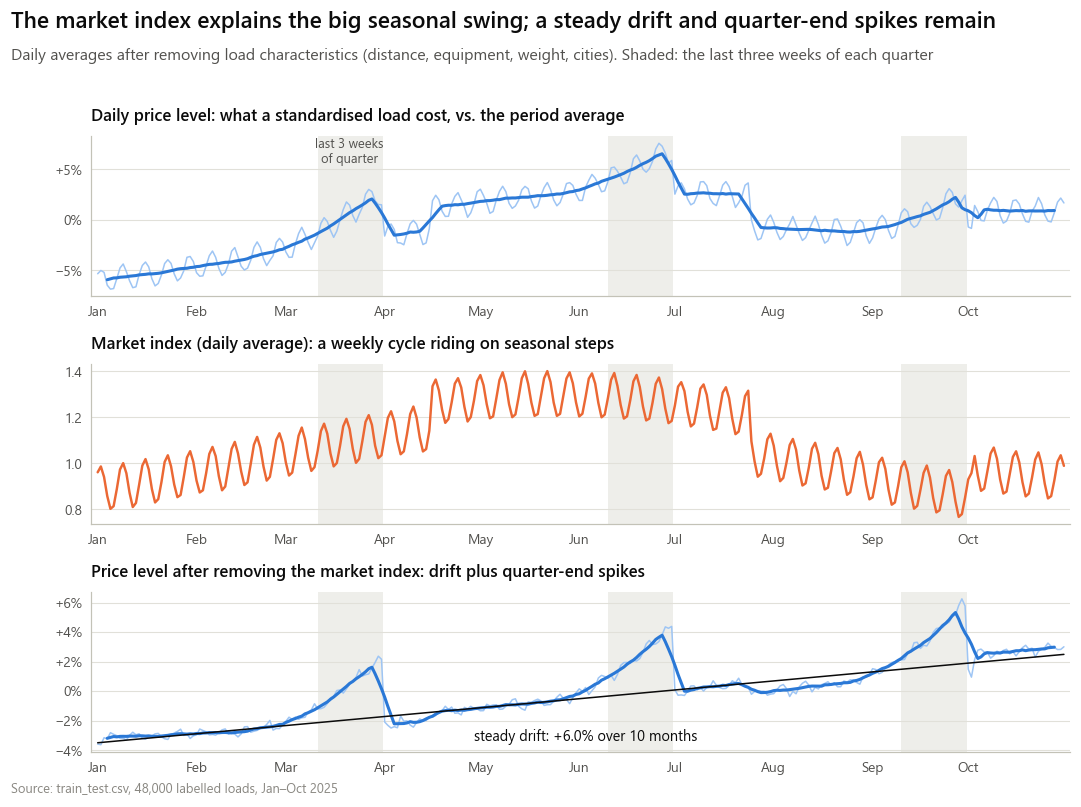

In [22]:
day["ex_mi"] = day.level - b_mi * (day.mi - day.mi.mean())
trend_fit = smf.ols("ex_mi ~ t", day[~day.qe_window]).fit()
qe_spans = [(pd.Timestamp(f"2025-{m:02d}-01") + pd.offsets.MonthEnd(0) - pd.Timedelta(days=20),
             pd.Timestamp(f"2025-{m:02d}-01") + pd.offsets.MonthEnd(0)) for m in (3, 6, 9)]

fig = plt.figure(figsize=(10, 7.4))
gs = fig.add_gridspec(3, 1, left=0.085, right=0.975, top=S.top(fig, 1.3), bottom=S.bottom(fig, 0.5), hspace=0.42)
axes = [fig.add_subplot(gs[i]) for i in range(3)]

def shade(ax):
    for a0, a1 in qe_spans:
        ax.axvspan(a0, a1 + pd.Timedelta(hours=12), color=S.GRID, alpha=0.55, lw=0, zorder=0)

ax = axes[0]
shade(ax)
ax.plot(day.index, day.level, color=S.BLUE_RAMP[1], lw=1)
ax.plot(day.index, day.level.rolling(7, center=True).mean(), color=S.BLUE, lw=2)
S.pct_axis(ax, "y", signed=True)
S.panel_title(ax, "Daily price level: what a standardised load cost, vs. the period average")

ax.yaxis.set_major_locator(MultipleLocator(0.05))

ax = axes[1]
shade(ax)
ax.plot(day.index, day.mi, color=S.ORANGE, lw=1.6)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.1f}"))
S.panel_title(ax, "Market index (daily average): a weekly cycle riding on seasonal steps")

ax = axes[2]
shade(ax)
ax.plot(day.index, day.ex_mi, color=S.BLUE_RAMP[1], lw=1)
ax.plot(day.index, day.ex_mi.rolling(7, center=True).mean(), color=S.BLUE, lw=2)
ax.plot(day.index, trend_fit.predict(day), color=S.INK, lw=1)
ax.text(day.index[118], trend_fit.predict(day).iloc[118] - 0.022,
        f"steady drift: {S.pct(b_t * day.t.max(), 1, signed=True)} over 10 months", fontsize=9.5, color=S.INK)
ax.yaxis.set_major_locator(MultipleLocator(0.02))
S.pct_axis(ax, "y", signed=True)
S.panel_title(ax, "Price level after removing the market index: drift plus quarter-end spikes")
a0, a1 = qe_spans[0]
axes[0].text(a0 + (a1 - a0) / 2, axes[0].get_ylim()[1] * 0.98, "last 3 weeks\nof quarter",
             ha="center", va="top", fontsize=8.5, color=S.INK_2)
for ax in axes:
    S.month_axis(ax)
    ax.set_xlim(day.index[0] - pd.Timedelta(days=2), day.index[-1] + pd.Timedelta(days=2))

S.headline(fig, "The market index explains the big seasonal swing; a steady drift and quarter-end spikes remain",
           "Daily averages after removing load characteristics (distance, equipment, weight, cities). "
           "Shaded: the last three weeks of each quarter")
S.footnote(fig)
S.save(fig, "08_price_over_time")
plt.show()

**What this means.** Market conditions move the whole price level by about 10% over the period (from roughly −5% in January to +5% in June, then down again in late summer), and `market_index` tracks that swing closely, including sudden steps (mid-April up, late July down) and a strong weekly cycle. Once the index is accounted for, two patterns remain: a **steady upward drift** of about 0.6% a month, and **sharp spikes at the end of each quarter**. The next section looks at those calendar effects.

### 3.4 Calendar effects: quarter ends and weekdays

In [23]:
day["e"] = day.level - fit_day.predict(day)

def around(ends, window):
    rows = []
    for end in pd.to_datetime(ends):
        for k in window:
            d = end + pd.Timedelta(days=int(k))
            if d in day.index:
                rows.append({"end": end, "k": k, "e": day.at[d, "e"]})
    return pd.DataFrame(rows)

qe = around(["2025-03-31", "2025-06-30", "2025-09-30"], range(-30, 21))
me = around(["2025-01-31", "2025-02-28", "2025-04-30", "2025-05-31", "2025-07-31", "2025-08-31"], range(-20, 11))
qe_mean = qe.groupby("k").e.mean()
me_mean = me.groupby("k").e.mean()
peak = qe_mean.loc[-3:0].mean()
print("Quarter-end pattern (mean of Mar, Jun, Sep):", qe_mean.loc[[-28, -21, -14, -7, -3, -1, 0, 1, 2, 7]].round(3).to_dict())
print(f"Peak premium in the last 4 days: {peak:+.1%}; first day of new quarter: {qe_mean.loc[1]:+.1%}")
print(f"Regular month-ends, last 4 days: {me_mean.loc[-3:0].mean():+.2%}")
DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
day["level_wk"] = day.level - day.level.rolling(7, center=True).mean()   # strip slow movement
day["mi_wk"] = day.mi - day.mi.rolling(7, center=True).mean()
calm = day[~day.qe_window].copy()
calm["after_mi"] = calm.level - smf.ols("level ~ mi + t", calm).fit().predict(calm)
dow_raw = calm.groupby("dow").level_wk.mean().set_axis(DAYS)
dow_after = calm.groupby("dow").after_mi.mean().set_axis(DAYS)
dow_raw -= dow_raw.mean()
dow_after -= dow_after.mean()
mi_week = calm.groupby("dow").mi_wk.mean().set_axis(DAYS)
print("Weekday pattern in price level:          ", dow_raw.round(4).to_dict())
print("Weekday pattern in market index:         ", mi_week.round(3).to_dict())
print("Weekday pattern left after market index: ", dow_after.round(4).to_dict())

Quarter-end pattern (mean of Mar, Jun, Sep): {-28: 0.002, -21: 0.009, -14: 0.017, -7: 0.03, -3: 0.035, -1: 0.04, 0: 0.039, 1: -0.002, 2: -0.004, 7: -0.001}
Peak premium in the last 4 days: +3.8%; first day of new quarter: -0.2%
Regular month-ends, last 4 days: -0.15%
Weekday pattern in price level:           {'Mon': -0.0097, 'Tue': -0.0018, 'Wed': 0.0081, 'Thu': 0.0119, 'Fri': 0.0065, 'Sat': -0.0039, 'Sun': -0.0111}
Weekday pattern in market index:          {'Mon': -0.085, 'Tue': -0.01, 'Wed': 0.074, 'Thu': 0.101, 'Fri': 0.052, 'Sat': -0.035, 'Sun': -0.096}
Weekday pattern left after market index:  {'Mon': 0.002, 'Tue': 0.0001, 'Wed': -0.0017, 'Thu': -0.002, 'Fri': -0.0008, 'Sat': 0.0005, 'Sun': 0.002}


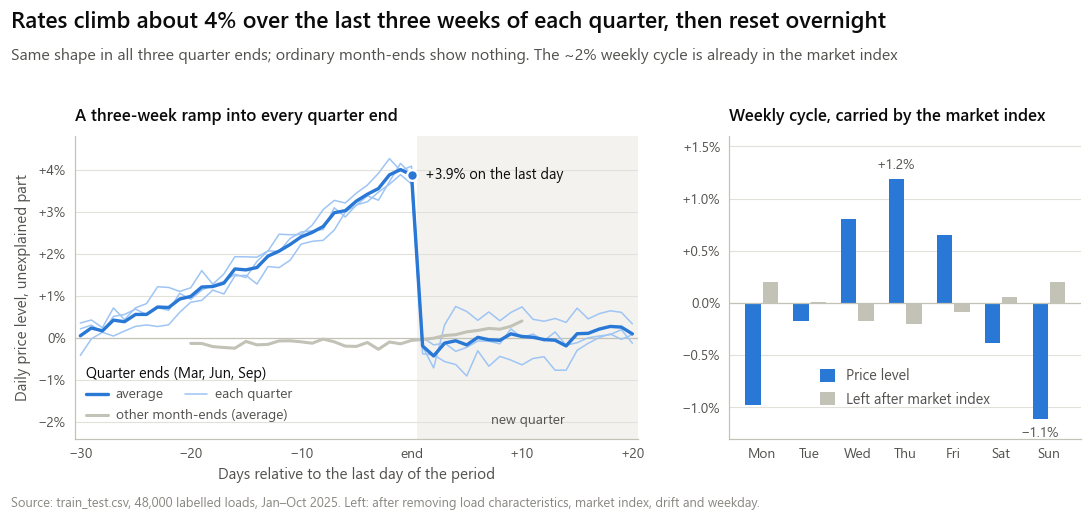

In [24]:
fig = plt.figure(figsize=(10, 4.8))
gs = fig.add_gridspec(1, 2, width_ratios=[1.6, 1], left=0.07, right=0.985,
                      top=S.top(fig, 1.3), bottom=S.bottom(fig, 0.75), wspace=0.2)

ax = fig.add_subplot(gs[0])
ax.axvspan(0.5, 20.5, color=S.GRID, alpha=0.4, lw=0)
ax.axhline(0, color=S.AXIS, lw=0.8)
for (end, g), shade_c in zip(qe.groupby("end"), [S.BLUE_RAMP[0], S.BLUE_RAMP[1], S.BLUE_RAMP[2]]):
    ax.plot(g.k, g.e, color=S.BLUE_RAMP[1], lw=1)
ax.plot(me_mean.index, me_mean.values, color=S.NEUTRAL, lw=2)
ax.plot(qe_mean.index, qe_mean.values, color=S.BLUE, lw=2.2)
ax.plot([0], [qe_mean.loc[0]], marker="o", ms=7, color=S.BLUE, mec=S.SURFACE, mew=1.5)
ax.text(1.2, qe_mean.loc[0], f"{S.pct(qe_mean.loc[0], 1, signed=True)} on the last day", ha="left", va="center",
        fontsize=9.5, color=S.INK)
ax.text(-29.5, -0.0085, "Quarter ends (Mar, Jun, Sep)", fontsize=9.5, color=S.INK, va="center")
ax.plot([-29.5, -27.5], [-0.0135, -0.0135], color=S.BLUE, lw=2.2)
ax.text(-26.8, -0.0135, "average", fontsize=9, color=S.INK_2, va="center")
ax.plot([-20.5, -18.5], [-0.0135, -0.0135], color=S.BLUE_RAMP[1], lw=1)
ax.text(-17.8, -0.0135, "each quarter", fontsize=9, color=S.INK_2, va="center")
ax.plot([-29.5, -27.5], [-0.0185, -0.0185], color=S.NEUTRAL, lw=2)
ax.text(-26.8, -0.0185, "other month-ends (average)", fontsize=9, color=S.INK_2, va="center")
ax.text(10.5, -0.0205, "new quarter", ha="center", fontsize=9, color=S.INK_2)
ax.set_xlim(-30.5, 20.5)
ax.set_ylim(-0.024, 0.048)
ax.yaxis.set_major_locator(MultipleLocator(0.01))
S.pct_axis(ax, "y", signed=True)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:+.0f}".replace("-", "−") if v else "end"))
ax.set_xlabel("Days relative to the last day of the period")
ax.set_ylabel("Daily price level, unexplained part")
S.panel_title(ax, "A three-week ramp into every quarter end")

ax = fig.add_subplot(gs[1])
xpos = np.arange(7)
bw = 0.32
ax.bar(xpos - bw / 2 - 0.02, dow_raw.values, width=bw, color=S.BLUE)
ax.bar(xpos + bw / 2 + 0.02, dow_after.values, width=bw, color=S.NEUTRAL)
ax.axhline(0, color=S.AXIS, lw=0.8)
ax.set_xticks(xpos, DAYS)
ax.set_ylim(-0.013, 0.016)
ax.yaxis.set_major_locator(MultipleLocator(0.005))
S.pct_axis(ax, "y", decimals=1, signed=True)
thu = DAYS.index("Thu")
ax.text(thu - 0.2, dow_raw["Thu"] + 0.0007, S.pct(dow_raw["Thu"], 1, signed=True), ha="center", va="bottom",
        fontsize=9, color=S.INK_2)
sun = DAYS.index("Sun")
ax.text(sun - 0.2, dow_raw["Sun"] - 0.0007, S.pct(dow_raw["Sun"], 1, signed=True), ha="center", va="top",
        fontsize=9, color=S.INK_2)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=S.BLUE, label="Price level"),
                   plt.Rectangle((0, 0), 1, 1, color=S.NEUTRAL, label="Left after market index")],
          loc="lower center", bbox_to_anchor=(0.5, 0.06), handlelength=1, handleheight=1)
S.panel_title(ax, "Weekly cycle, carried by the market index")

S.headline(fig, f"Rates climb about {peak:.0%} over the last three weeks of each quarter, then reset overnight",
           "Same shape in all three quarter ends; ordinary month-ends show nothing. "
           "The ~2% weekly cycle is already in the market index")
S.footnote(fig, S.SOURCE_NOTE + ". Left: after removing load characteristics, market index, drift and weekday.")
S.save(fig, "09_calendar_effects")
plt.show()

**What this means.** In every quarter, prices start climbing about three weeks before the quarter ends, peak around +4% on the last days, and drop back the very next day. The pattern repeats almost identically in March, June and September, and ordinary month-ends show nothing, so it's a genuine quarter-end effect, not noise.

Prices also have a **weekly rhythm** (Thursday the priciest, Sunday the cheapest, about 2% apart). The market index rises and falls on exactly the same weekly cycle, so once the index is accounted for nothing is left. The weekday pattern is already "inside" `market_index`.

December, the month of the chart in the brief, is also a quarter end (and a year end).

### 3.5 The two market signals: `market_index` vs `quote_signal`

Plotting 47,000 individual loads would be a cloud of noise, so loads are sorted by each signal and split into 10 equal-sized groups (deciles, ~4,700 loads each). For each group we take the average signal and the average price relative to similar loads. If the dots climb from left to right, higher values of the signal go with higher prices.

In [25]:
sig = clean.dropna(subset=["market_index"]).copy()
sig["r_load"] -= sig.r_load.mean()
mi_dec = sig.groupby(pd.qcut(sig.market_index, 10), observed=True).agg(x=("market_index", "mean"), r=("r_load", "mean"))
qs_dec = sig.groupby(pd.qcut(sig.quote_signal, 10), observed=True).agg(x=("quote_signal", "mean"), r=("r_load", "mean"))
mi_span, qs_span = mi_dec.r.max() - mi_dec.r.min(), qs_dec.r.max() - qs_dec.r.min()
r_mi, r_qs = sig.r_load.corr(sig.market_index), sig.r_load.corr(sig.quote_signal)
within = lambda col: sig[col] - sig.groupby("date")[col].transform("mean")
r_qs_within = within("r_load").corr(within("quote_signal"))
r_mi_within = within("r_load").corr(within("market_index"))
print(f"Correlation with price level: market_index {r_mi:.2f}, quote_signal {r_qs:.2f}")
print(f"Within the same day: market_index {r_mi_within:.2f}, quote_signal {r_qs_within:.2f}")
print(f"Price difference between the lowest and highest of 10 groups: market_index {mi_span:.1%}, quote_signal {qs_span:.1%}")
print(f"Daily average quote_signal vs. daily price level: {day.qs.corr(day.level):.2f}")
print(f"Does quote_signal know about the corrupted prices? corr with log(actual/expected) on flagged rows: "
      f"{np.log(df.loc[df.corrupt, 'ratio']).corr(df.loc[df.corrupt, 'quote_signal']):.2f}")

Correlation with price level: market_index 0.61, quote_signal 0.08
Within the same day: market_index 0.16, quote_signal 0.11
Price difference between the lowest and highest of 10 groups: market_index 6.5%, quote_signal 1.9%
Daily average quote_signal vs. daily price level: 0.08
Does quote_signal know about the corrupted prices? corr with log(actual/expected) on flagged rows: 0.03


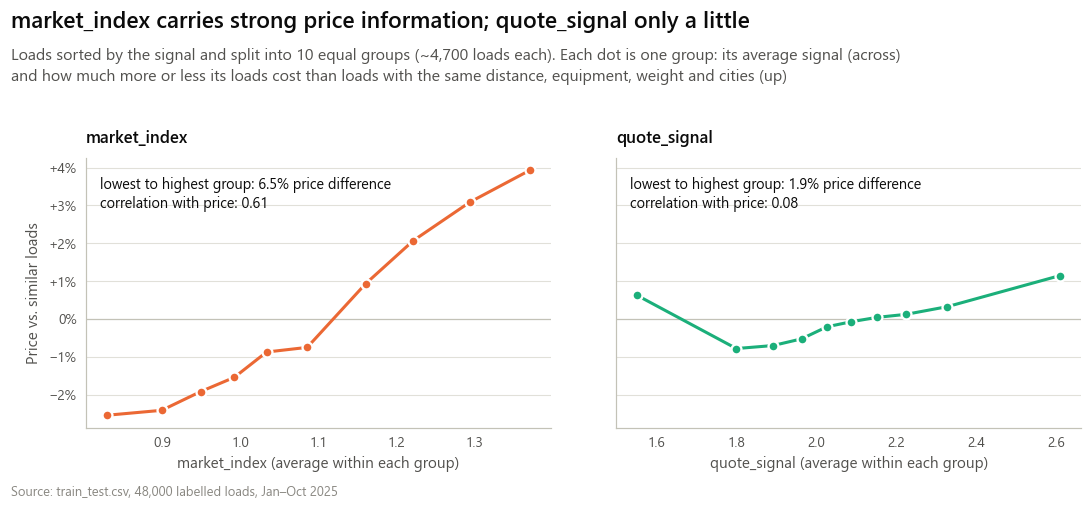

In [26]:
fig = plt.figure(figsize=(10, 4.7))
gs = fig.add_gridspec(1, 2, left=0.08, right=0.985, top=S.top(fig, 1.5), bottom=S.bottom(fig, 0.75), wspace=0.14)
ax0 = fig.add_subplot(gs[0])
ax1 = fig.add_subplot(gs[1], sharey=ax0)
for ax, dec, color, name, span, r in [(ax0, mi_dec, S.ORANGE, "market_index", mi_span, r_mi),
                                      (ax1, qs_dec, S.AQUA, "quote_signal", qs_span, r_qs)]:
    ax.axhline(0, color=S.AXIS, lw=0.8)
    ax.plot(dec.x, dec.r, color=color, lw=2, marker="o", ms=6.5, mec=S.SURFACE, mew=1.5)
    ax.set_xlabel(f"{name} (average within each group)")
    ax.text(0.03, 0.93, f"lowest to highest group: {span:.1%} price difference\ncorrelation with price: {r:.2f}",
            transform=ax.transAxes, va="top", fontsize=9.5, color=S.INK)
    S.panel_title(ax, name)
ax0.set_ylabel("Price vs. similar loads")
S.pct_axis(ax0, "y", signed=True)
plt.setp(ax1.get_yticklabels(), visible=False)

S.headline(fig, "market_index carries strong price information; quote_signal only a little",
           "Loads sorted by the signal and split into 10 equal groups (~4,700 loads each). Each dot is one group: its average signal (across)\n"
           "and how much more or less its loads cost than loads with the same distance, equipment, weight and cities (up)")
S.footnote(fig)
S.save(fig, "10_market_signals")
plt.show()

**What this means.** `market_index` is a strong signal: loads in its top tenth cost about 6–7% more than those in its bottom tenth, for the same kind of load, and it tracks the day-to-day market closely. `quote_signal` is much weaker: price moves only ~2% across its whole range, with a slight upward slope and an odd uptick in the lowest tenth. Its link to price is small but not zero, and it shows up within a single day too, so it may carry a little load-level information. It shows no relationship with the corrupted prices, so it isn't secretly derived from the label.

### 3.6 How noisy is pricing?

If we account for everything found so far (distance, equipment, weight, market index, cities, drift, quarter-end ramp, weekday), how big is the leftover variation, and does it depend on the size of the load?

In [27]:
clean["qe_ramp"] = ((21 - clean.days_to_qend) / 21).clip(lower=0) * clean.date.dt.month.isin([3, 6, 9, 12])
FULL = ("log_rate ~ bs(log_dist, df=6) + C(equipment) + bs(w_k, df=5) + mi_fill + t + qe_ramp + C(dow)"
        " + C(pickup) + C(delivery)")
fit_full = smf.ols(FULL, clean).fit()
clean["r_full"] = clean.log_rate - fit_full.predict(clean)
clean["err_usd"] = clean.posted_rate - np.exp(fit_full.predict(clean))
dd = pd.qcut(clean.distance, 8)
noise = clean.groupby(dd, observed=True).agg(d_lo=("distance", "min"), d_hi=("distance", "max"),
                                             pct=("r_full", "std"), usd=("err_usd", "std"), rate=("posted_rate", "median"))
print(noise.round(3).to_string())
print(f"Overall leftover variation: {clean.r_full.std():.1%} of the rate")
with_qs = smf.ols(FULL + " + quote_signal", clean).fit()
print(f"Adding quote_signal to this fit: leftover {fit_full.resid.std():.3%} -> {with_qs.resid.std():.3%}")

                      d_lo    d_hi    pct     usd      rate
distance                                                   
(69.999, 367.025]     70.0   367.0  0.019  12.879   671.060
(367.025, 550.8]     367.1   550.8  0.019  20.405  1084.970
(550.8, 752.0]       550.9   752.0  0.018  27.416  1459.755
(752.0, 954.1]       752.1   954.1  0.018  34.203  1831.520
(954.1, 1212.0]      954.2  1212.0  0.019  42.785  2253.715
(1212.0, 1647.6]    1212.1  1647.6  0.018  53.517  2883.780
(1647.6, 2104.175]  1647.7  2104.1  0.019  70.222  3741.480
(2104.175, 3439.8]  2104.2  3439.8  0.019  93.180  4725.395
Overall leftover variation: 1.9% of the rate


Adding quote_signal to this fit: leftover 1.868% -> 1.853%


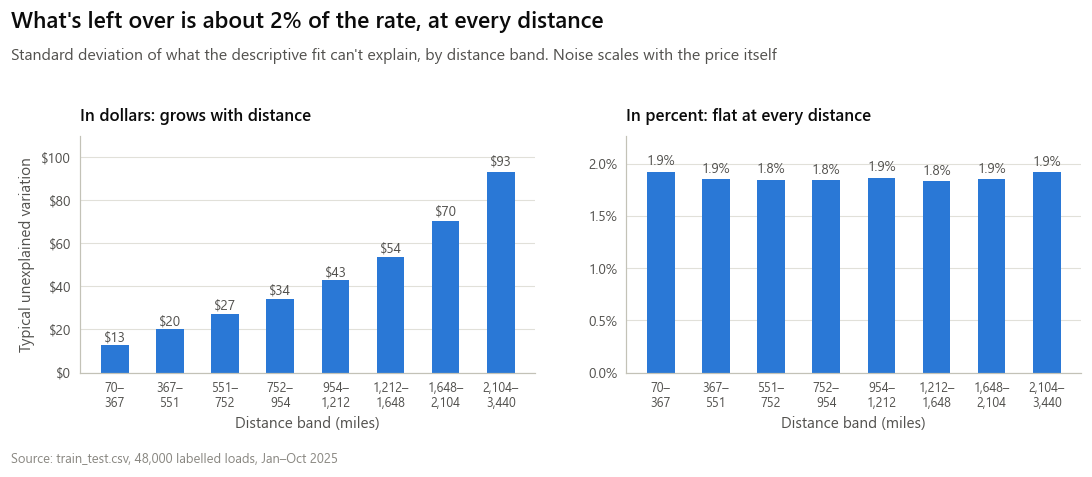

In [28]:
fig = plt.figure(figsize=(10, 4.4))
gs = fig.add_gridspec(1, 2, left=0.075, right=0.985, top=S.top(fig, 1.3), bottom=S.bottom(fig, 0.95), wspace=0.2)
labels = [f"{lo:,.0f}–\n{hi:,.0f}" for lo, hi in zip(noise.d_lo, noise.d_hi)]
x = np.arange(len(noise))
for i, (col, title, fmt) in enumerate([("usd", "In dollars: grows with distance", lambda v: f"${v:,.0f}"),
                                       ("pct", "In percent: flat at every distance", lambda v: f"{v:.1%}")]):
    ax = fig.add_subplot(gs[i])
    ax.bar(x, noise[col], width=0.5, color=S.BLUE)
    for xi, v in zip(x, noise[col]):
        ax.text(xi, v * 1.02, fmt(v), ha="center", va="bottom", fontsize=8.8, color=S.INK_2)
    ax.set_xticks(x, labels)
    ax.tick_params(axis="x", labelsize=8.3)
    ax.set_xlabel("Distance band (miles)")
    ax.set_ylim(0, noise[col].max() * 1.18)
    if col == "usd":
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:,.0f}"))
        ax.set_ylabel("Typical unexplained variation")
    else:
        ax.yaxis.set_major_locator(MultipleLocator(0.005))
        S.pct_axis(ax, "y", decimals=1)
    S.panel_title(ax, title)

S.headline(fig, f"What's left over is about {clean.r_full.std():.0%} of the rate, at every distance",
           "Standard deviation of what the descriptive fit can't explain, by distance band. Noise scales with the price itself")
S.footnote(fig)
S.save(fig, "11_noise")
plt.show()

**What this means.** The unexplained part of the price is a roughly constant *percentage* (~2%), so in dollars it grows with distance: about $13 on a short haul, over $90 on a cross-country load. Price noise is **multiplicative**: error measured in percent treats a $300 and a $6,000 load alike, whereas dollar error is dominated by long hauls. Adding `quote_signal` on top of everything barely changes the leftover (see the printout above).

### 3.7 Putting it together: how much does each factor explain?

Adding the factors one at a time to the descriptive fit shows how much each one tightens the typical error. (The order matters a little; this illustrates relative importance.)

In [29]:
steps = [
    ("Distance", "log_rate ~ bs(log_dist, df=6)"),
    ("+ Equipment", " + C(equipment)"),
    ("+ Weight", " + bs(w_k, df=5)"),
    ("+ Market index", " + mi_fill"),
    ("+ Pickup & delivery city", " + C(pickup) + C(delivery)"),
    ("+ Calendar (drift, quarter end, weekday)", " + t + qe_ramp + C(dow)"),
]
formula, ladder = "", []
for name, term in steps:
    formula += term
    ladder.append((name, smf.ols(formula, clean).fit().resid.std()))
ladder = pd.Series(dict(ladder))
no_info = clean.log_rate.std()
print(f"No information at all: typical spread of log price {no_info:.0%}")
print(ladder.map("{:.2%}".format).to_string())

No information at all: typical spread of log price 65%
Distance                                    7.32%
+ Equipment                                 5.00%
+ Weight                                    4.35%
+ Market index                              3.75%
+ Pickup & delivery city                    2.83%
+ Calendar (drift, quarter end, weekday)    1.87%


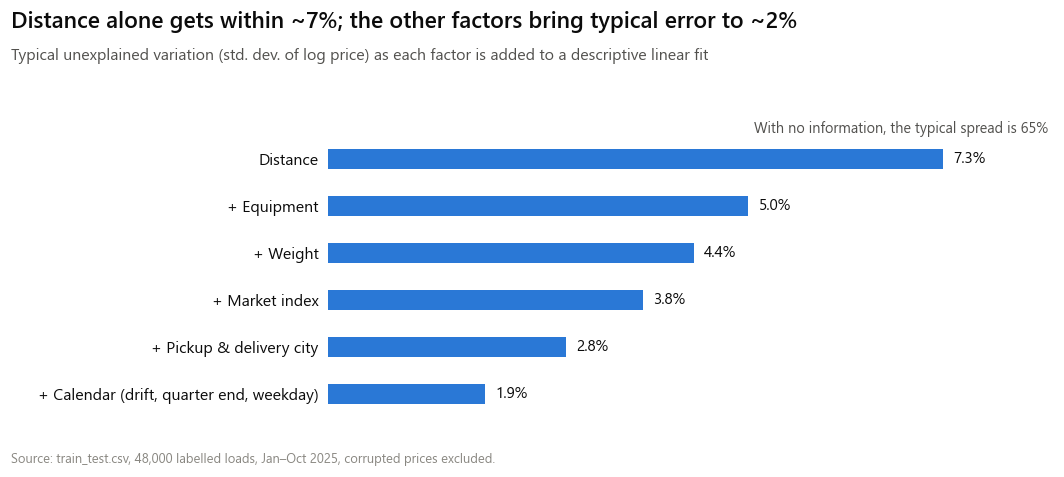

In [30]:
fig = plt.figure(figsize=(10, 4.4))
ax = fig.add_axes([0.3, S.bottom(fig, 0.55), 0.66, S.top(fig, 1.3) - S.bottom(fig, 0.55)])
y = np.arange(len(ladder))[::-1]
ax.barh(y, ladder.values, height=0.42, color=S.BLUE)
for yi, (name, v) in zip(y, ladder.items()):
    ax.text(v + 0.0012, yi, f"{v:.1%}", va="center", fontsize=10, color=S.INK)
ax.set_yticks(y, ladder.index)
ax.tick_params(axis="y", labelsize=10.5, labelcolor=S.INK)
ax.set_xlim(0, ladder.max() * 1.18)
ax.xaxis.set_major_locator(NullLocator())
ax.grid(False)
for side in ("bottom", "left"):
    ax.spines[side].set_visible(False)
ax.text(ladder.max() * 1.17, y[0] + 0.55, f"With no information, the typical spread is {no_info:.0%}",
        ha="right", fontsize=9.5, color=S.INK_2)
S.headline(fig, f"Distance alone gets within ~{ladder.iloc[0]:.0%}; the other factors bring typical error to ~{ladder.iloc[-1]:.0%}",
           "Typical unexplained variation (std. dev. of log price) as each factor is added to a descriptive linear fit")
S.footnote(fig, S.SOURCE_NOTE + ", corrupted prices excluded.")
S.save(fig, "12_what_drives_price")
plt.show()

## 4 · Summary

### Data-quality issues
| Issue | Loads | What the evidence shows |
|---|---|---|
| Posted rate off by 2–6× | 677 (1.4%) | Random multiplicative corruption, cleanly separated from normal prices; these labels are unreliable |
| Weight capped at 47,500 lb | 1,204 (2.5%) | Heavier loads recorded as the cap; they price like the heaviest uncapped loads, so little information is lost |
| Negative weight | 292 (0.6%) | Sign flip; the absolute value prices exactly like a normal weight |
| Weight missing | 300 (0.6%) | Random; these loads price like average loads |
| Market index missing | 374 (0.8%) | Random; the index is mostly a daily value, so the same day's loads carry it |
| Distance at 70-mile floor | 48 (0.1%) | Very short lanes clamped to 70 mi |
| Weight at 5,000 lb floor | 32 (0.1%) | Light loads clamped |

### What drives the price
1. **Distance** dominates: a fixed charge plus a per-mile rate, so per-mile prices fall with distance.
2. **Equipment** is a constant percentage premium: Reefer ≈ +13%, Flatbed ≈ +8% over Dry Van.
3. **Weight** adds up to ~8%, S-shaped (flat when light, steep 20–40K lb, flat when heavy).
4. **Market index** tracks the market's daily level (≈ 10% seasonal swing, sudden steps, and a ~2% weekly cycle).
5. **Location** adds a smooth regional effect of up to ±4%, identical for origin and destination.
6. **Calendar:** a steady upward drift (~0.6%/month) and a ~4% ramp into every quarter end that resets the next day. The weekday cycle is already captured by the market index.
7. **`quote_signal`** carries a little information at most.
8. After all of this, roughly **2% multiplicative noise** remains, the same percentage at every distance.